In [1]:
import tensorflow as tf
import os

os.chdir('/home/maria-luna')

train_ds = tf.keras.utils.image_dataset_from_directory(
    'dataset/train',
    image_size=(224, 224),
    batch_size=16,
    label_mode='categorical',
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    'dataset/val',
    image_size=(224, 224),
    batch_size=16,
    label_mode='categorical',
    shuffle=False
)

clases = train_ds.class_names
print("Clases:", clases)
print("Batches train:", len(train_ds))
print("Batches val:", len(val_ds))

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds   = val_ds.prefetch(tf.data.AUTOTUNE)

I0000 00:00:1778904182.761148    5975 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1778904182.814079    5975 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1778904184.135613    5975 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Found 759 files belonging to 5 classes.
Found 163 files belonging to 5 classes.
Clases: ['capacitor', 'diodo', 'led', 'resistencia', 'transistor']
Batches train: 48
Batches val: 11


E0000 00:00:1778904185.539797    5975 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [2]:
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

base_model = tf.keras.applications.EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = layers.RandomRotation(0.2)(inputs)
x = layers.RandomFlip("horizontal")(x)
x = layers.RandomZoom(0.15)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(clases), activation='softmax')(x)

model = tf.keras.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
print("✓ Modelo listo")

✓ Modelo listo


In [3]:
callbacks = [
    EarlyStopping(patience=7, restore_best_weights=True, verbose=1),
    ModelCheckpoint('mejor_modelo.keras', save_best_only=True, verbose=1)
]

history = model.fit(
    train_ds,
    epochs=30,
    validation_data=val_ds,
    callbacks=callbacks,
    verbose=1
)
print("✓ Entrenamiento completo")

Epoch 1/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 504ms/step - accuracy: 0.2816 - loss: 1.6322
Epoch 1: val_loss improved from None to 1.16984, saving model to mejor_modelo.keras

Epoch 1: finished saving model to mejor_modelo.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 41s 674ms/step - accuracy: 0.3702 - loss: 1.4981 - val_accuracy: 0.6135 - val_loss: 1.1698
Epoch 2/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 516ms/step - accuracy: 0.5584 - loss: 1.1902
Epoch 2: val_loss improved from 1.16984 to 1.02191, saving model to mejor_modelo.keras

Epoch 2: finished saving model to mejor_modelo.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 31s 639ms/step - accuracy: 0.5639 - loss: 1.1672 - val_accuracy: 0.6319 - val_loss: 1.0219
Epoch 3/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 535ms/step - accuracy: 0.6263 - loss: 0.9882
Epoch 3: val_loss improved from 1.02191 to 0.93866, saving model to mejor_modelo.keras

Epoch 3: finished saving model to mejor_modelo.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 32s 658ms/step - accuracy: 0.6179 - loss: 1.0057 - val_accu

In [4]:
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_ft = [
    EarlyStopping(patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint('mejor_modelo_ft.keras', save_best_only=True, verbose=1)
]

print("Iniciando fine-tuning...")
history_ft = model.fit(
    train_ds,
    epochs=20,
    validation_data=val_ds,
    callbacks=callbacks_ft,
    verbose=1
)
print("✓ Fine-tuning completo")

Iniciando fine-tuning...
Epoch 1/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7122 - loss: 0.8118
Epoch 1: val_loss improved from None to 0.67887, saving model to mejor_modelo_ft.keras

Epoch 1: finished saving model to mejor_modelo_ft.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.7365 - loss: 0.7563 - val_accuracy: 0.7853 - val_loss: 0.6789
Epoch 2/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7341 - loss: 0.7242
Epoch 2: val_loss did not improve from 0.67887
48/48 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step - accuracy: 0.7444 - loss: 0.6901 - val_accuracy: 0.7485 - val_loss: 0.7070
Epoch 3/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7664 - loss: 0.6147
Epoch 3: val_loss did not improve from 0.67887
48/48 ━━━━━━━━━━━━━━━━━━━━ 59s 1s/step - accuracy: 0.7918 - loss: 0.5738 - val_accuracy: 0.7423 - val_loss: 0.7205
Epoch 4/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7721 - loss: 0.6289
Epoch 4: val_loss did not improve from 0.67887
48/48 ━━━━━━━

In [11]:
callbacks = [
    EarlyStopping(patience=7, restore_best_weights=True, verbose=1),
    ModelCheckpoint('mejor_modelo.keras', save_best_only=True, verbose=1)
]

history = model.fit(
    train_ds,
    epochs=30,
    validation_data=val_ds,
    callbacks=callbacks,
    verbose=1
)

print("✓ Entrenamiento completo")

Epoch 1/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 505ms/step - accuracy: 0.3213 - loss: 1.5925
Epoch 1: val_loss improved from None to 1.40294, saving model to mejor_modelo.keras

Epoch 1: finished saving model to mejor_modelo.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 29s 758ms/step - accuracy: 0.3548 - loss: 1.5076 - val_accuracy: 0.4661 - val_loss: 1.4029
Epoch 2/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 516ms/step - accuracy: 0.5408 - loss: 1.2383
Epoch 2: val_loss improved from 1.40294 to 1.21779, saving model to mejor_modelo.keras

Epoch 2: finished saving model to mejor_modelo.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 19s 747ms/step - accuracy: 0.5757 - loss: 1.1781 - val_accuracy: 0.5169 - val_loss: 1.2178
Epoch 3/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 513ms/step - accuracy: 0.5874 - loss: 1.0743
Epoch 3: val_loss improved from 1.21779 to 1.14115, saving model to mejor_modelo.keras

Epoch 3: finished saving model to mejor_modelo.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 19s 745ms/step - accuracy: 0.6203 - loss: 1.0284 - val_accu

In [12]:
# Descongelar las últimas 20 capas de la base
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Recompilar con learning rate más pequeño
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_ft = [
    EarlyStopping(patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint('mejor_modelo_ft.keras', save_best_only=True, verbose=1)
]

print("Iniciando fine-tuning...")
history_ft = model.fit(
    train_ds,
    epochs=20,
    validation_data=val_ds,
    callbacks=callbacks_ft,
    verbose=1
)

print("✓ Fine-tuning completo")

Iniciando fine-tuning...
Epoch 1/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 652ms/step - accuracy: 0.7022 - loss: 0.8481
Epoch 1: val_loss improved from None to 0.99150, saving model to mejor_modelo_ft.keras

Epoch 1: finished saving model to mejor_modelo_ft.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 37s 974ms/step - accuracy: 0.7122 - loss: 0.8369 - val_accuracy: 0.6610 - val_loss: 0.9915
Epoch 2/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 660ms/step - accuracy: 0.7807 - loss: 0.7555
Epoch 2: val_loss did not improve from 0.99150
26/26 ━━━━━━━━━━━━━━━━━━━━ 22s 865ms/step - accuracy: 0.7643 - loss: 0.7599 - val_accuracy: 0.6525 - val_loss: 0.9967
Epoch 3/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 622ms/step - accuracy: 0.7318 - loss: 0.7526
Epoch 3: val_loss improved from 0.99150 to 0.99118, saving model to mejor_modelo_ft.keras

Epoch 3: finished saving model to mejor_modelo_ft.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 21s 804ms/step - accuracy: 0.7320 - loss: 0.7684 - val_accuracy: 0.7034 - val_loss: 0.9912
Epoch 4/20
26/26 ━━━━━━━━

Found 120 files belonging to 5 classes.


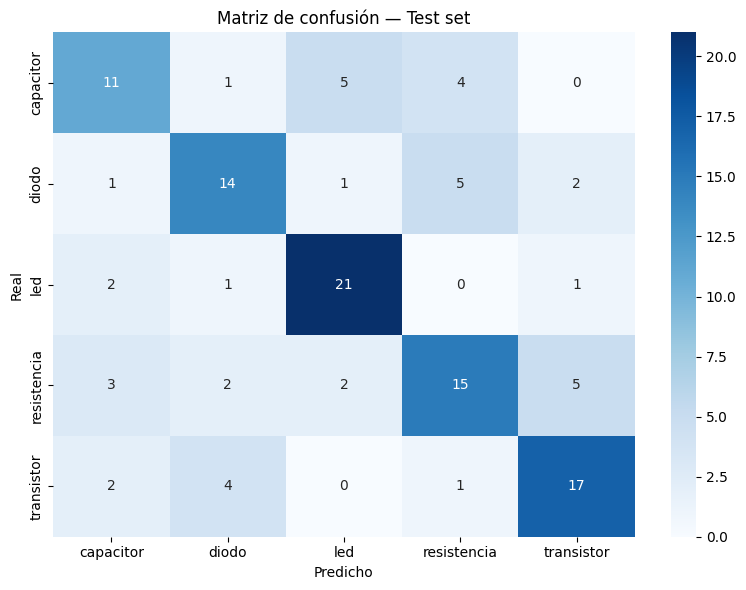


               precision    recall  f1-score   support

   capacitor       0.58      0.52      0.55        21
       diodo       0.64      0.61      0.62        23
         led       0.72      0.84      0.78        25
 resistencia       0.60      0.56      0.58        27
  transistor       0.68      0.71      0.69        24

    accuracy                           0.65       120
   macro avg       0.64      0.65      0.64       120
weighted avg       0.65      0.65      0.65       120



In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Cargar el mejor modelo
mejor_modelo = tf.keras.models.load_model('mejor_modelo_ft.keras')

# Predecir en el conjunto de test
test_ds = tf.keras.utils.image_dataset_from_directory(
    '/home/maria-luna/dataset/test',
    image_size=(224, 224),
    batch_size=16,
    label_mode='categorical',
    shuffle=False
)

y_true, y_pred = [], []
for imgs, labels in test_ds:
    preds = mejor_modelo.predict(imgs, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

# Matriz de confusión
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=clases, yticklabels=clases)
plt.title('Matriz de confusión — Test set')
plt.ylabel('Real')
plt.xlabel('Predicho')
plt.tight_layout()
plt.savefig('matriz_confusion.png', dpi=100)
plt.show()

# Reporte detallado
print("\n", classification_report(y_true, y_pred, target_names=clases))

In [15]:
from PIL import Image
import numpy as np

def predecir_componente(ruta_imagen):
    img = Image.open(ruta_imagen).convert('RGB').resize((224, 224))
    arr = np.array(img, dtype=np.float32)
    arr = np.expand_dims(arr, axis=0)
    
    pred = mejor_modelo.predict(arr, verbose=0)
    idx = np.argmax(pred)
    confianza = pred[0][idx] * 100
    
    print(f"Componente: {clases[idx].upper()}")
    print(f"Confianza:  {confianza:.1f}%")
    print()
    for i, c in enumerate(clases):
        barra = '█' * int(pred[0][i] * 30)
        print(f"  {c:12} {pred[0][i]*100:5.1f}% {barra}")
    
    return clases[idx]

# Prueba con una imagen del test set
import os
test_img = '/home/maria-luna/dataset/test/led/' + os.listdir('/home/maria-luna/dataset/test/led/')[0]
print(f"Imagen: {test_img}\n")
predecir_componente(test_img)

Imagen: /home/maria-luna/dataset/test/led/000105.jpg

Componente: DIODO
Confianza:  68.4%

  capacitor      4.9% █
  diodo         68.4% ████████████████████
  led            5.5% █
  resistencia   12.3% ███
  transistor     8.8% ██


'diodo'

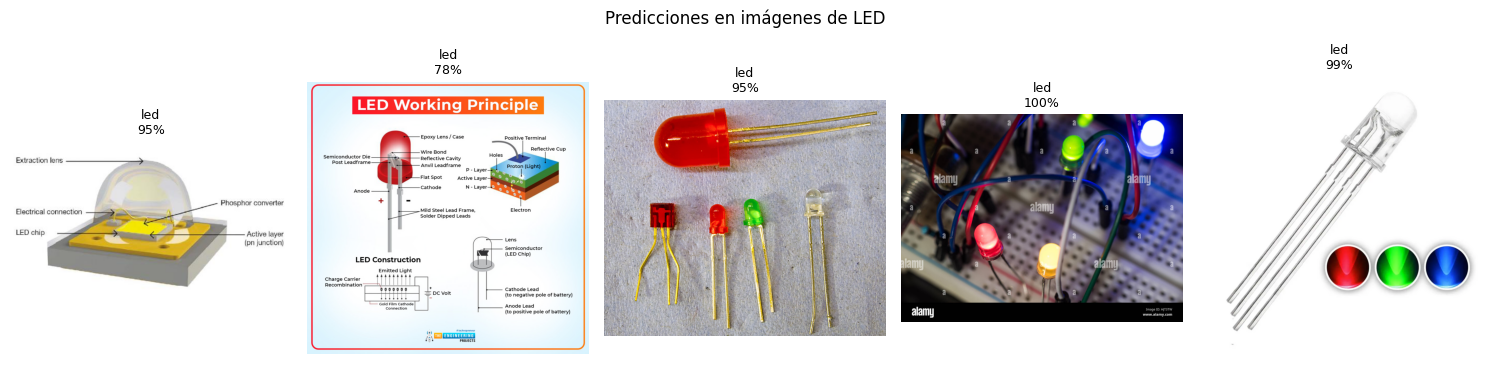

In [18]:
# Probar varias imágenes y ver cuáles son fotos reales
imagenes_prueba = ['000072.jpg', '000003.jpg', '000059.jpg', '000018.jpg', '000055.jpg']

fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for i, fname in enumerate(imagenes_prueba):
    ruta = f'/home/maria-luna/dataset/test/led/{fname}'
    img = Image.open(ruta).convert('RGB')
    pred = mejor_modelo.predict(np.expand_dims(np.array(img.resize((224,224)), dtype=np.float32), axis=0), verbose=0)
    clase_pred = clases[np.argmax(pred)]
    confianza = np.max(pred) * 100
    axes[i].imshow(img)
    axes[i].set_title(f'{clase_pred}\n{confianza:.0f}%', fontsize=9)
    axes[i].axis('off')

plt.suptitle('Predicciones en imágenes de LED', fontsize=12)
plt.tight_layout()
plt.show()